In [2]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

In [3]:
data = pd.read_parquet("C:/Users/tommy/OneDrive/Documents/GitHub/data-science-capstone/Data/cleaned_data/merged.parguet", engine="fastparquet")
data = data.dropna()
data

,interval_start_utc,interval_end_utc,publish_time_utc,north_derated_outages_mw,north_forced_outages_mw,north_planned_outages_mw,north_unplanned_outages_mw,central_derated_outages_mw,central_forced_outages_mw,central_planned_outages_mw,...,south_wind,miso_wind,north_solar,central_solar,south_solar,miso_solar,lmp_dam,energy_dam,congestion_dam,loss_dam
0,2023-03-25 01:55:00+00:00,2023-03-25 02:00:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,9920.8,3.9,1.0,1.2,6.1,26.92,26.09,1.66,-0.83
1,2023-03-25 02:00:00+00:00,2023-03-25 02:05:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
2,2023-03-25 02:05:00+00:00,2023-03-25 02:10:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
3,2023-03-25 02:10:00+00:00,2023-03-25 02:15:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
4,2023-03-25 02:15:00+00:00,2023-03-25 02:20:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
366307,2026-09-16 23:30:00+00:00,2026-09-16 23:35:00+00:00,2026-09-15 05:00:00+00:00,1641.0,1812.0,3536.0,99.0,6771.0,4415.0,10190.0,...,48.8,3865.8,98.9,684.2,645.1,1428.2,159.93,390.14,-220.71,-9.50
366308,2026-09-16 23:35:00+00:00,2026-09-16 23:40:00+00:00,2026-09-15 05:00:00+00:00,1641.0,1812.0,3536.0,99.0,6771.0,4415.0,10190.0,...,48.8,3865.8,98.9,684.2,645.1,1428.2,159.93,390.14,-220.71,-9.50
366309,2026-09-16 23:40:00+00:00,2026-09-16 23:45:00+00:00,2026-09-15 05:00:00+00:00,1641.0,1812.0,3536.0,99.0,6771.0,4415.0,10190.0,...,48.8,3865.8,98.9,684.2,645.1,1428.2,159.93,390.14,-220.71,-9.50
366310,2026-09-16 23:45:00+00:00,2026-09-16 23:50:00+00:00,2026-09-15 05:00:00+00:00,1641.0,1812.0,3536.0,99.0,6771.0,4415.0,10190.0,...,48.8,3865.8,98.9,684.2,645.1,1428.2,159.93,390.14,-220.71,-9.50


In [4]:
#cap price at 132
data["lmp_rtm"] = data["lmp_rtm"].clip(upper=132)

#convert timestamp to datetime
data["interval_end_utc"] = pd.to_datetime(data["interval_end_utc"], utc=True, errors="coerce")

#set cutoff for data split and validation
test_start = pd.Timestamp("2026-01-01", tz="UTC")
validation_start = pd.Timestamp("2025-07-01", tz="UTC")

#create the training, testing, and validation data
train_data = data.loc[data["interval_end_utc"] < validation_start].copy()
test_data = data.loc[data["interval_end_utc"] >= test_start].copy()
validation_data = data.loc[
    (data["interval_end_utc"] >= validation_start) &
    (data["interval_end_utc"] < test_start)
].copy()

#show number of rows each category holds
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Testing rows:", len(test_data))

#Split features
features = ["energy_dam", "congestion_dam", "loss_dam", "miso_wind", "miso_solar", "miso_derated_outages_mw", "miso_forced_outages_mw", "miso_planned_outages_mw", "miso_unplanned_outages_mw"]

X_test = test_data[features]
y_test = test_data["lmp_rtm"]

X_train = train_data[features]
y_train = train_data["lmp_rtm"]

X_val = validation_data[features]
y_val = validation_data["lmp_rtm"]

#random forest regression
model = ExtraTreesRegressor(n_estimators=300, max_features=1, min_samples_split=2, min_samples_leaf=2, random_state=1)
model.fit(X_train, y_train)
val_prediction = model.predict(X_val)

#evaluate validation results
rf_mae = mean_absolute_error(y_val, val_prediction)
rf_rmse = math.sqrt(mean_squared_error(y_val, val_prediction))
rf_r2 = r2_score(y_val, val_prediction)
print("\nValidation Results")
print("RMSE: ", rf_rmse)
print("MAE: ", rf_mae)
print("R2: ", rf_r2)

Training rows: 230966
Validation rows: 51831
Testing rows: 71923

Validation Results
RMSE:  21.34359178408288
MAE:  12.91073819955077
R2:  0.3238312662979266


In [5]:
#Comparing the test data
test_predict = model.predict(X_test)

rf_mae = mean_absolute_error(y_test, test_predict)
rf_rmse = math.sqrt(mean_squared_error(y_test, test_predict))
rf_r2 = r2_score(y_test, test_predict)
print("Test Results")
print("RMSE: ", rf_rmse)
print("MAE: ", rf_mae)
print("R2: ", rf_r2)

Test Results
RMSE:  22.639529649718998
MAE:  15.196335018913564
R2:  0.284665625244407


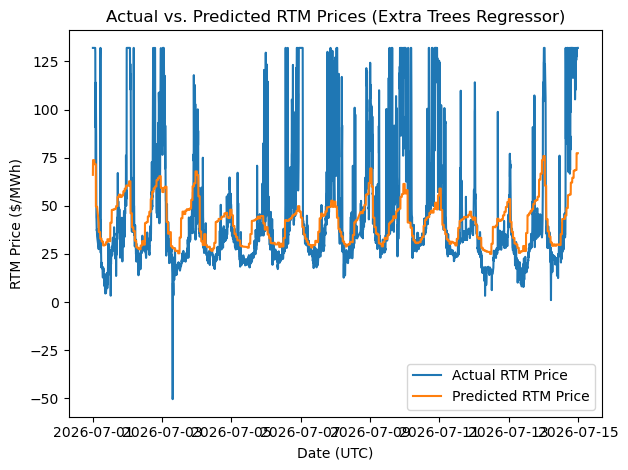

In [9]:
#Plotting the data
test_results = test_data[["interval_end_utc", "lmp_rtm"]].copy()
test_results["predicted"] = test_predict

#show results for only 1 month
month_start = pd.Timestamp("2026-07-01", tz="UTC")
month_end = pd.Timestamp("2026-07-15", tz="UTC")
monthly_results = test_results.loc[
    (test_results["interval_end_utc"] >= month_start) &
    (test_results["interval_end_utc"] < month_end)
]


plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["lmp_rtm"],
    label = "Actual RTM Price"
)

plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["predicted"],
    label = "Predicted RTM Price"
)


plt.xlabel("Date (UTC)")
plt.ylabel("RTM Price ($/MWh)")
plt.title("Actual vs. Predicted RTM Prices (Extra Trees Regressor)")
plt.legend()
plt.tight_layout()
plt.show()

**Forecast Vectors**

In [6]:
#creating the price forecast vectors
FORECAST_HORIZON = 288
STRIDE_STEPS = 240

#place to store forecast vectors
validation_vectors = {}

for start in range(0, len(validation_data) - FORECAST_HORIZON + 1, STRIDE_STEPS):
    #select feature window
    X_window = X_val.iloc[start:start + FORECAST_HORIZON]

    #make predictions for this window
    predictions = model.predict(X_window)

    #get starting timestamp
    start_time = validation_data["interval_end_utc"].iloc[start]

    #store predictions
    validation_vectors[start_time] = predictions

print("Number of validation vectors:", len(validation_vectors))

Number of validation vectors: 215


In [7]:
print(validation_vectors)

{Timestamp('2025-07-01 00:00:00+0000', tz='UTC'): array([30.11909091, 47.32628657, 47.32628657, 47.32628657, 47.32628657,
       47.32628657, 47.32628657, 47.32628657, 47.32628657, 47.32628657,
       47.32628657, 47.32628657, 47.32628657, 44.05971485, 44.05971485,
       44.05971485, 44.05971485, 44.05971485, 44.05971485, 44.05971485,
       44.05971485, 44.05971485, 44.05971485, 44.05971485, 44.05971485,
       38.67926   , 38.67926   , 38.67926   , 38.67926   , 38.67926   ,
       38.67926   , 38.67926   , 38.67926   , 38.67926   , 38.67926   ,
       38.67926   , 38.67926   , 35.93503182, 35.93503182, 35.93503182,
       35.93503182, 35.93503182, 35.93503182, 35.93503182, 35.93503182,
       35.93503182, 35.93503182, 35.93503182, 35.93503182, 32.63948561,
       32.63948561, 32.63948561, 32.63948561, 32.63948561, 32.63948561,
       32.63948561, 32.63948561, 32.63948561, 32.63948561, 32.63948561,
       32.63948561, 32.21346338, 32.21346338, 32.21346338, 32.21346338,
       32.2134

**Evaluating the Forecast Vectors**

In [8]:
#RMSE for each forecast horizon
horizon_rmse = []
actual_prices = validation_data["lmp_rtm"].to_numpy()

#map each timestamp to its integer row position
timestamp_to_position = {
    timestamp: i
    for i, timestamp in enumerate(validation_data["interval_end_utc"])
}

for horizon in range(FORECAST_HORIZON):
    actual_values = []
    predicted_values = []
    for start_time, predictions in validation_vectors.items():

        #find vector starting row
        start_index = timestamp_to_position[start_time]

        #get actual price at this forecast horizon
        actual = actual_prices[start_index + horizon]
        actual_values.append(actual)
        predicted_values.append(predictions[horizon])
    #get RMSE for this horizon
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))
    horizon_rmse.append(rmse)

#prints the results for 
rmse_results = pd.DataFrame({"Forecast Horizon" : range(1, FORECAST_HORIZON + 1), "RMSE" : horizon_rmse})
print(rmse_results)

     Forecast Horizon       RMSE
0                   1  20.213231
1                   2  19.831625
2                   3  17.447093
3                   4  17.631612
4                   5  18.226318
..                ...        ...
283               284  23.087652
284               285  22.742200
285               286  20.185343
286               287  22.166426
287               288  22.201782

[288 rows x 2 columns]
